In [1]:
%pip install pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
print("Experiment 10: Employee Salary Prediction")
print("Jupyter Notebook is working correctly!")

Experiment 10: Employee Salary Prediction
Jupyter Notebook is working correctly!


In [4]:
import pandas as pd

data = {
    "YearsExperience": [
        1.1, 1.3, 1.5, 2.0, 2.2,
        2.9, 3.0, 3.2, 3.2, 3.7,
        3.9, 4.0, 4.0, 4.1, 4.5,
        4.9, 5.1, 5.3, 5.9, 6.0,
        6.8, 7.1, 7.9, 8.2, 8.7,
        9.0, 9.5, 9.6, 10.3, 10.5
    ],
    "Salary": [
        39343, 46205, 37731, 43525, 39891,
        56642, 60150, 54445, 64445, 57189,
        63218, 55794, 56957, 57081, 61111,
        67938, 66029, 83088, 81363, 93940,
        91738, 98273, 101302, 113812, 109431,
        105582, 116969, 112635, 122391, 121872
    ]
}

df = pd.DataFrame(data)

df.to_csv("Salary_Data.csv", index=False)

print("CSV file created successfully!")
print(df.head())


CSV file created successfully!
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891


In [5]:
# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

# 2. Load Dataset
df = pd.read_csv("Salary_Data.csv")

print("\nEMPLOYEE SALARY DATASET")
print("-----------------------")
print(df.head())

print("\nDataset Shape:", df.shape)

Libraries imported successfully!

EMPLOYEE SALARY DATASET
-----------------------
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Dataset Shape: (30, 2)


In [6]:

# 3. Check Missing Values
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
YearsExperience    0
Salary             0
dtype: int64


In [7]:

# 4. Define Input and Target

X = df[["YearsExperience"]]
y = df["Salary"]

print("Input (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())



Input (X):
   YearsExperience
0              1.1
1              1.3
2              1.5
3              2.0
4              2.2

Target (y):
0    39343
1    46205
2    37731
3    43525
4    39891
Name: Salary, dtype: int64


In [8]:

# 5. Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 24
Testing samples: 6


In [9]:

# 6. Create Linear Regression Model

model = LinearRegression()

print("Linear Regression model created successfully!")



Linear Regression model created successfully!


In [10]:

# 7. Train Model

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [11]:

# 8. Predict Salary

y_pred = model.predict(X_test)

print("Predicted Salaries:")
print(y_pred)



Predicted Salaries:
[115790.21011287  71498.27809463 102596.86866063  75267.80422384
  55477.79204548  60189.69970699]


In [12]:

# 9. Model Evaluation

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("MODEL PERFORMANCE")
print("------------------")
print("R² Score:", round(r2, 4))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))



MODEL PERFORMANCE
------------------
R² Score: 0.9024
MAE: 6286.45
RMSE: 7059.04


In [13]:

# 10. Regression Equation

print("REGRESSION EQUATION")
print("-------------------")

print(
    f"Salary = {model.coef_[0]:.2f} "
    f"* YearsExperience + {model.intercept_:.2f}"
)


REGRESSION EQUATION
-------------------
Salary = 9423.82 * YearsExperience + 25321.58


In [14]:

# 11. Actual vs Predicted Salary

result = pd.DataFrame({
    "ActualSalary": y_test.values,
    "PredictedSalary": np.round(y_pred, 2)
})

print("ACTUAL VS PREDICTED SALARY")
print("--------------------------")
print(result)



ACTUAL VS PREDICTED SALARY
--------------------------
   ActualSalary  PredictedSalary
0        112635        115790.21
1         67938         71498.28
2        113812        102596.87
3         83088         75267.80
4         64445         55477.79
5         57189         60189.70


In [15]:

# 12. Predict Salary for New Employees

new_employees = pd.DataFrame({
    "YearsExperience": [2.5, 5, 7, 10]
})

new_predictions = model.predict(new_employees)

print("NEW EMPLOYEE SALARY PREDICTION")
print("------------------------------")

for experience, salary in zip(
    new_employees["YearsExperience"],
    new_predictions
):
    print(
        f"{experience} Years Experience -> "
        f"Predicted Salary: ₹{salary:,.2f}"
    )



NEW EMPLOYEE SALARY PREDICTION
------------------------------
2.5 Years Experience -> Predicted Salary: ₹48,881.12
5.0 Years Experience -> Predicted Salary: ₹72,440.66
7.0 Years Experience -> Predicted Salary: ₹91,288.29
10.0 Years Experience -> Predicted Salary: ₹119,559.74


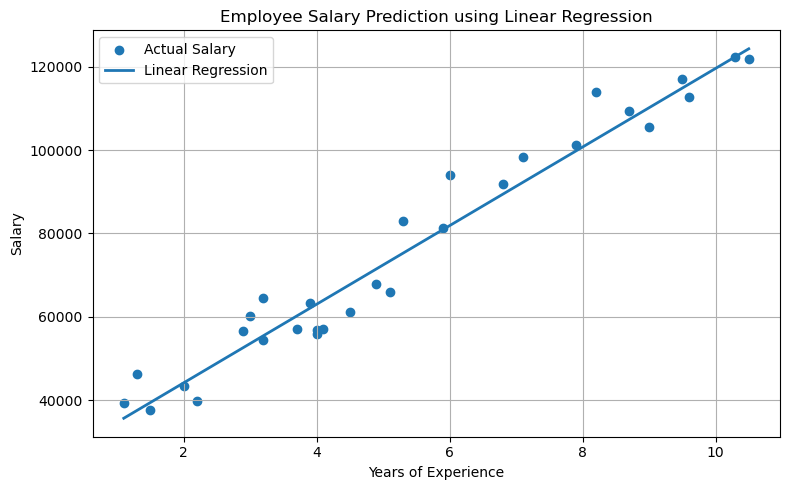

In [16]:

# 13. Visualization

plt.figure(figsize=(8, 5))

plt.scatter(
    X["YearsExperience"],
    y,
    label="Actual Salary"
)

plt.plot(
    X["YearsExperience"],
    model.predict(X),
    linewidth=2,
    label="Linear Regression"
)

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Employee Salary Prediction using Linear Regression")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
